# Chemical synthesis: predicting nanoparticle size and shape from the recipe

**Question.** Given a *chemical-synthesis recipe* reported in a paper (reagents, concentrations, temperature, time, stirring), can we predict the **size** and **shape** of the nanoparticles, for a paper the model has never seen?

This notebook redoes my initial analysis with a stricter workflow. The differences from the first version:

| Initial notebook | This notebook |
|---|---|
| Random 80/20 split of rows | **Paper-grouped** repeated cross-validation (all rows of a paper stay together) |
| Imputed *before* splitting, and imputed the **targets** | Rows with a missing target are **dropped**; imputation lives **inside** the CV pipeline |
| Concentrations in mixed units, side by side | Converted to **mM** where the unit is molar; the rest are flagged as missing |
| Label-encoded categories | **Domain-informed classes** (reducing-agent type, stabiliser type, nanoparticle family) + one-hot |
| Raw size as target (max 1,140 nm) | **log10(size)**, errors reported as "fold error" |
| No baselines | Global and per-family **baselines**; paired bootstrap over papers |
| Impurity importances | **Permutation importance on held-out papers** |

**Workflow:** 1 load → 2 audit → 3 clean → 4 feature engineering → 5 EDA → 6 evaluation protocol → 7 size models → 8 ablation & importance → 9 shape models → 10 conclusions.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import np_utils as U

U.set_style()
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_colwidth", 60)
DATA = Path("../data/Nanoparticles_Synthesis_Dataset - Chemical_Synthesis.xlsx")
SEED = 42
N_REPEATS = 5          # repeated 5-fold CV; raise to 10+ for tighter intervals

## 1. Load and repair text

Spreadsheet exports contain mis-decoded characters (`Â°C`, `Â·`, `â‚‚`). We repair them so that names and column titles are readable. Nothing about the *values* changes.

In [2]:
raw = pd.read_excel(DATA)
raw.columns = [U.fix_text(c) for c in raw.columns]
for c in raw.columns:
    if not pd.api.types.is_numeric_dtype(raw[c]):
        raw[c] = raw[c].map(U.fix_text)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head(3)

166 rows x 26 columns


,NanoParticles,Precursor Feeding Rate (ml/min),Precursor,Precursor Concentration,Unit,Reducing Agent,Reducing Agent Concentration,Unit2,Stabilizing Agent,Stabilizing Agent Concentration,Unit3,Temperature(°C),Pressure,Calcination Temperature,Calcination Time(hr),PH of Reaction Mixture,Agitation,Stirring rate(rpm),Time(min),Average Size(nm),Min Size(nm),Max Size(nm),Method to record sizes,Shape,Reference,Title of Article
0,CuMoO4,2.5,Cu2+ solution,0.005,mM,MoO42- aq solution,0.005,mM,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,Vigorous Stirring,NaN,NaN,98,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure characterization...
1,CuMoO4,10.0,Cu2+ solution,0.005,mM,MoO42- aq solution,0.01,mM,NaN,NaN,NaN,30.0,NaN,NaN,NaN,NaN,Vigorous Stirring,NaN,NaN,11,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure characterization...
2,CuMoO4,40.0,Cu2+ solution,0.005,mM,MoO42- aq solution,0.1,mM,NaN,NaN,NaN,60.0,NaN,NaN,NaN,NaN,Vigorous Stirring,NaN,NaN,80,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure characterization...


## 2. Data audit

Before touching anything: how complete is each column, and how many different papers do the rows come from? Rows from one paper are **not independent** (the same lab, the same method, the same instrument), which is why we group by paper later.

In [3]:
audit = pd.DataFrame({
    "missing_%": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
}).sort_values("missing_%", ascending=False)
display(audit)

# paper identifier: article title; fall back to the reference id; fall back to a unique id per row
df = raw.copy()
df["paper"] = df["Title of Article"]
df["paper"] = df["paper"].fillna("ref_" + df["Reference"].astype("string"))
df["paper"] = [p if isinstance(p, str) and "<NA>" not in p and p != "ref_nan" else f"row_{i}"
               for i, p in zip(df.index, df["paper"])]
per_paper = df.groupby("paper").size()
print(f"\n{df['paper'].nunique()} papers; rows per paper: median {per_paper.median():.0f}, max {per_paper.max()}")

,missing_%,n_unique,example
Pressure,84.3,6,Standard atmospheric pressure
Calcination Time(hr),81.9,8,2.0
Precursor Feeding Rate (ml/min),79.5,10,2.5
Calcination Temperature,79.5,8,200.0
Max Size(nm),69.9,25,60.0
Min Size(nm),69.9,20,20.0
Stirring rate(rpm),66.3,11,110
PH of Reaction Mixture,64.5,14,7.5
Unit3,50.6,15,M
Stabilizing Agent Concentration,49.4,22,1.28



46 papers; rows per paper: median 2, max 18


**Decision: columns with more than ~50% missing values are not used** (feeding rate, pressure, calcination, pH, stirring rate, min/max size). They carry too little information to learn from, and mean-imputing them would invent data.

## 3. Cleaning

**Targets first.**
* `size_nm` comes from `Average Size(nm)` (ranges such as `5-30` become their midpoint).
* `shape_group` is `spherical` (anything described as spherical, quasi- or pseudo-spherical) versus `non-spherical`. The raw shape labels have 1–6 examples each, too few to learn a 10-way classifier.
* **Rows with a missing target are dropped, never imputed.** An imputed target makes the model "predict" a number it was handed.

In [4]:
df["size_nm"] = df["Average Size(nm)"].map(U.parse_number)
df.loc[~(df["size_nm"] > 0), "size_nm"] = np.nan
df["log_size"] = np.log10(df["size_nm"])

def shape_group(s):
    if not isinstance(s, str) or not s.strip():
        return np.nan
    return "spherical" if "spher" in s.lower() else "non-spherical"
df["shape_group"] = df["Shape"].map(shape_group)

print("size available :", df["size_nm"].notna().sum(), "of", len(df))
print("shape available:", df["shape_group"].notna().sum(), "of", len(df))
display(pd.crosstab(df["Shape"].str.strip().str.lower().fillna("(missing)"), df["shape_group"].fillna("(missing)")))

size available : 147 of 166
shape available: 103 of 166


shape_group,(missing),non-spherical,spherical
Shape,,,
(missing),63,0,0
cubic,0,3,0
ellipsoidal,0,6,0
irregular,0,13,0
longitudinal and rectangular flat plates,0,6,0
nano-flower,0,1,0
nanoplates,0,1,0
nanoprisms,0,1,0
pseudospherical,0,0,1


**Units.** Concentrations come with a separate unit column (`M`, `mM`, `g/ml`, `wt%`, ...). Putting `0.005 mM` and `0.005 M` into one column, as the first version did, is a 1000-fold error. We convert **molar** units to mM. Mass- and percentage-based concentrations cannot be converted without molar masses, so they become *missing* (and the model receives a "was missing" flag).

In [5]:
UNIT_TO_MM = {"M": 1000.0, "mol": 1000.0,      # 'mol' is read as mol/L (assumption)
              "mM": 1.0, "Mm": 1.0}             # 'Mm' is a typo for mM (assumption)

def to_mM(value, unit):
    v = U.parse_number(value)
    f = UNIT_TO_MM.get(str(unit).strip(), np.nan)
    return v * f if (np.isfinite(v) and v > 0) else np.nan

df["precursor_mM"]  = [to_mM(v, u) for v, u in zip(df["Precursor Concentration"], df["Unit"])]
df["reducer_mM"]    = [to_mM(v, u) for v, u in zip(df["Reducing Agent Concentration"], df["Unit2"])]
df["stabilizer_mM"] = [to_mM(v, u) for v, u in zip(df["Stabilizing Agent Concentration"], df["Unit3"])]

for name, valcol, mmcol in [("precursor", "Precursor Concentration", "precursor_mM"),
                            ("reducing agent", "Reducing Agent Concentration", "reducer_mM"),
                            ("stabiliser", "Stabilizing Agent Concentration", "stabilizer_mM")]:
    has_value = df[valcol].map(U.parse_number).notna().sum()
    print(f"{name:15s}: {has_value:3d} reported -> {df[mmcol].notna().sum():3d} usable in mM "
          f"({has_value - df[mmcol].notna().sum()} in non-molar or missing units)")

precursor      : 152 reported -> 125 usable in mM (27 in non-molar or missing units)
reducing agent : 148 reported -> 118 usable in mM (30 in non-molar or missing units)
stabiliser     :  84 reported ->  38 usable in mM (46 in non-molar or missing units)


**Other numeric columns and label hygiene.** Temperature and time are parsed; the nanoparticle name is reduced to its **primary metal family** (the raw sheet has `AgNps`, `AgNPs`, `Ag NPs`, `AgO NPs` as four separate categories).

In [6]:
df["temperature_C"] = df["Temperature(°C)"].map(U.parse_number)
df["time_min"] = df["Time(min)"].map(U.parse_number)

def np_family(name):
    n = str(name).lower()
    if "silver" in n or n.startswith("ag"):  return "Ag"
    if "gold" in n or n.startswith("au"):    return "Au"
    if "iron" in n or n.startswith("fe"):    return "Fe oxide"
    if "copper" in n or n.startswith("cu"):  return "Cu"
    if "zinc" in n or n.startswith("zn"):    return "Zn"
    if n.startswith(("pt", "pd")) or "platinum" in n or "palladium" in n: return "Pt/Pd"
    return "other"
df["np_family"] = df["NanoParticles"].map(np_family)
display(pd.crosstab(df["NanoParticles"], df["np_family"]).T.style.format(precision=0) if False else
        df.groupby("np_family")["NanoParticles"].agg(lambda s: ", ".join(sorted(set(s))[:6])).to_frame("raw labels (first 6)"))

,raw labels (first 6)
np_family,
Ag,"Ag NPs, AgNPs, AgNps, AgO NPs, Cu-doped silver iodide"
Au,"Au NPs, Gold nanoparticles"
Cu,"Copper Tungstate NPs, Cu, Cu (Copper), Cu₂O, CuO, CuMoO4..."
Fe oxide,"Fe3O4 Nanoparticles, Iron Oxide, Iron oxide"
Pt/Pd,"PdRu, Platinum (Pt) nanoparticles, Platinum-Palladium (P..."
Zn,"ZnO, ZnO NPs"
other,"CdS Nanoparticles, Ce-doped SnO2, CeO2-NPs, NiO Nanopart..."


## 4. Feature engineering (chemistry-informed)

Instead of integer-coding 26 different reducing agents, we use what a chemist would: **what kind** of reducing agent (a strong one like borohydride gives small, fast-nucleating particles; a mild one like citrate gives larger ones), **what kind** of stabiliser (polymer, surfactant, small ion), the **molar ratio** of reducer to precursor, and so on.

In [7]:
def reducer_class(s):
    n = str(s).lower()
    if "nabh4" in n or "borohydride" in n:                       return "borohydride"
    if "hydrazine" in n:                                         return "hydrazine"
    if "ascorbic" in n:                                          return "ascorbic acid"
    if "citrate" in n or "tsc" in n:                             return "citrate"
    if any(k in n for k in ["glucose", "dextran", "chitosan", "aldehyde", "sugar"]): return "sugar / biopolymer"
    if any(k in n for k in ["naoh", "nh4oh", "hydroxide"]):      return "base"
    if any(k in n for k in ["oxalic", "gallic", "glycine"]):     return "organic acid"
    if any(k in n for k in ["ethanol", "polyol", "dmf"]):        return "alcohol / solvent"
    if "extract" in n:                                           return "plant extract"
    return "other"

def stabilizer_class(s):
    if not isinstance(s, str) or not s.strip():
        return "none reported"
    n = s.lower()
    if any(k in n for k in ["pvp", "polyvinyl", "pva", "peg", "polyethylene", "chitosan", "starch", "dextran", "gelatin"]): return "polymer"
    if any(k in n for k in ["ctab", "cetyl", "sds", "dodecyl", "aot", "surfactin", "hexadecyl", "oleyl"]):                  return "surfactant"
    if any(k in n for k in ["citr", "tsc", "oxalic", "gallic"]):                                                             return "citrate / acid"
    return "other"

def agitation_class(s):
    if not isinstance(s, str) or not s.strip():
        return "not reported"
    n = s.lower()
    if "vigorous" in n:   return "vigorous stirring"
    if "magnetic" in n:   return "magnetic stirring"
    if "mechanical" in n: return "mechanical"
    if "stirring" in n:   return "stirring"
    return "other"

def method_class(s):
    n = str(s).upper()
    if "SEM" in n:                       return "SEM"
    if n in ("TEM", "AFM", "DLS"):       return n
    if "XRD" in n:                       return "XRD"
    if n in ("PSD", "PSA"):              return "particle-size analyser"
    return "other"

df["reducer_class"]    = df["Reducing Agent"].map(reducer_class)
df["stabilizer_class"] = df["Stabilizing Agent"].map(stabilizer_class)
df["agitation_class"]  = df["Agitation"].map(agitation_class)
df["measurement"]      = df["Method to record sizes"].map(method_class)

log10 = lambda s: np.log10(s.where(s > 0))
df["log_precursor_mM"]  = log10(df["precursor_mM"])
df["log_reducer_mM"]    = log10(df["reducer_mM"])
df["log_stabilizer_mM"] = log10(df["stabilizer_mM"])
df["log_reducer_to_precursor"] = log10(df["reducer_mM"] / df["precursor_mM"])
df["log_time_min"]      = log10(df["time_min"])
df["has_stabilizer"]    = df["Stabilizing Agent"].notna().astype(int)

NUM = ["log_precursor_mM", "log_reducer_mM", "log_stabilizer_mM", "log_reducer_to_precursor",
       "temperature_C", "log_time_min", "has_stabilizer"]
CAT = ["np_family", "reducer_class", "stabilizer_class", "agitation_class"]
MEAS = ["measurement"]              # a property of the *characterisation*, not of the synthesis; tested separately
print("numeric :", NUM); print("category:", CAT); print("measurement:", MEAS)
display(df[CAT + MEAS].apply(lambda s: s.value_counts().to_dict()).to_frame("counts"))

numeric : ['log_precursor_mM', 'log_reducer_mM', 'log_stabilizer_mM', 'log_reducer_to_precursor', 'temperature_C', 'log_time_min', 'has_stabilizer']
category: ['np_family', 'reducer_class', 'stabilizer_class', 'agitation_class']
measurement: ['measurement']


,counts
np_family,"{'Ag': 76, 'Cu': 42, 'Fe oxide': 20, 'Au': 9, 'other': 8..."
reducer_class,"{'borohydride': 31, 'base': 28, 'citrate': 26, 'other': ..."
stabilizer_class,"{'none reported': 71, 'polymer': 44, 'citrate / acid': 2..."
agitation_class,"{'magnetic stirring': 55, 'not reported': 45, 'stirring'..."
measurement,"{'SEM': 44, 'TEM': 41, 'DLS': 22, 'other': 21, 'particle..."


**Modelling tables.** One table per task. Each has the engineered features, the target, and the paper id (used only for splitting).

In [8]:
FEATURES = NUM + CAT + MEAS
size_df  = df.dropna(subset=["log_size"]).reset_index(drop=True)
shape_df = df.dropna(subset=["shape_group"]).reset_index(drop=True)
shape_df["is_nonspherical"] = (shape_df["shape_group"] == "non-spherical").astype(int)

print(f"SIZE : {len(size_df)} rows from {size_df['paper'].nunique()} papers")
print(f"SHAPE: {len(shape_df)} rows from {shape_df['paper'].nunique()} papers, "
      f"{shape_df['is_nonspherical'].sum()} non-spherical ({shape_df['is_nonspherical'].mean():.0%})")
print("\nremaining missingness in engineered features (size table):")
display((size_df[NUM].isna().mean() * 100).round(1).to_frame("missing %").T)

SIZE : 147 rows from 39 papers
SHAPE: 103 rows from 34 papers, 38 non-spherical (37%)

remaining missingness in engineered features (size table):


,log_precursor_mM,log_reducer_mM,log_stabilizer_mM,log_reducer_to_precursor,temperature_C,log_time_min,has_stabilizer
missing %,19.0,23.8,74.1,30.6,19.0,21.1,0.0


## 5. Exploratory analysis

Three things to see: what the target looks like (and why we take logs), whether the nanoparticle family already explains much of it, and how the numeric features relate to size.

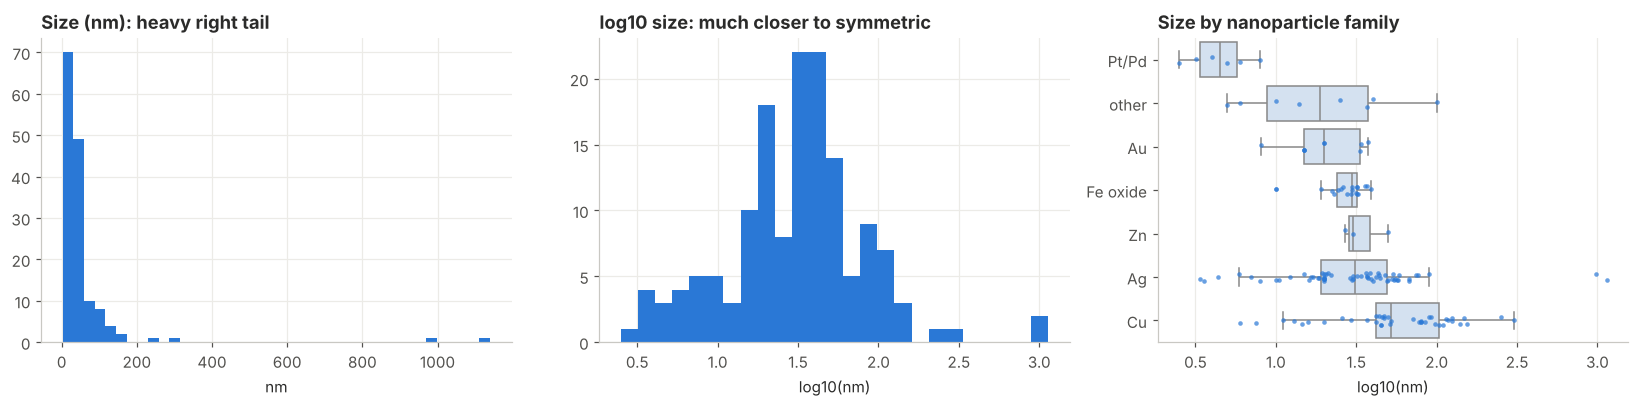

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(size_df["size_nm"], bins=40, color=U.BLUE); ax[0].set_title("Size (nm): heavy right tail"); ax[0].set_xlabel("nm")
ax[1].hist(size_df["log_size"], bins=25, color=U.BLUE); ax[1].set_title("log10 size: much closer to symmetric"); ax[1].set_xlabel("log10(nm)")
order = size_df.groupby("np_family")["log_size"].median().sort_values().index
sns.boxplot(data=size_df, y="np_family", x="log_size", order=order, color="#cfe0f5", fliersize=0, ax=ax[2], linewidth=1)
sns.stripplot(data=size_df, y="np_family", x="log_size", order=order, color=U.BLUE, size=3, alpha=.7, ax=ax[2])
ax[2].set_title("Size by nanoparticle family"); ax[2].set_xlabel("log10(nm)"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

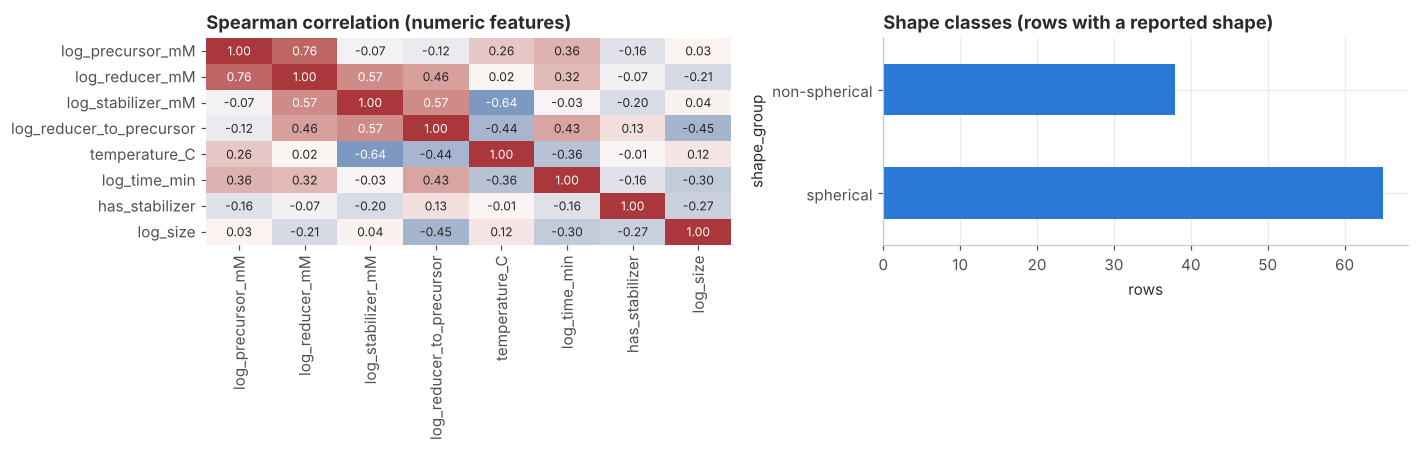

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
corr = size_df[NUM + ["log_size"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False, ax=ax[0], annot_kws={"size": 8})
ax[0].set_title("Spearman correlation (numeric features)")
(shape_df["shape_group"].value_counts().plot.barh(color=U.BLUE, ax=ax[1]))
ax[1].set_title("Shape classes (rows with a reported shape)"); ax[1].set_xlabel("rows")
plt.tight_layout(); plt.show()

### 5b. How much of the variation is "which paper", and what does changing a knob do inside one paper?

Two diagnostics that explain the modelling results further down.

* **ICC** is the share of variance in log-size that is explained purely by *which paper a row comes from* (lab, instrument, reporting habits). A high ICC means much of the signal is not about the recipe.
* **Within-paper effects** remove each paper's own mean from both the feature and the target, then correlate what is left. This answers the chemist's question, "when the *same lab* turns this one knob, does size go up or down?", without between-paper confounding.

ICC (share of log-size variance explained by paper identity): 0.57


,within_paper_rho,ci_low,ci_high,n_papers,n_rows
feature,,,,,
log_precursor_mM,0.48,0.15,0.75,6,61
log_reducer_mM,0.36,-0.01,0.68,6,65
log_stabilizer_mM,NaN,NaN,NaN,2,21
log_reducer_to_precursor,NaN,NaN,NaN,3,26
temperature_C,0.01,-0.46,0.34,5,34
log_time_min,-0.03,-0.61,0.58,4,21


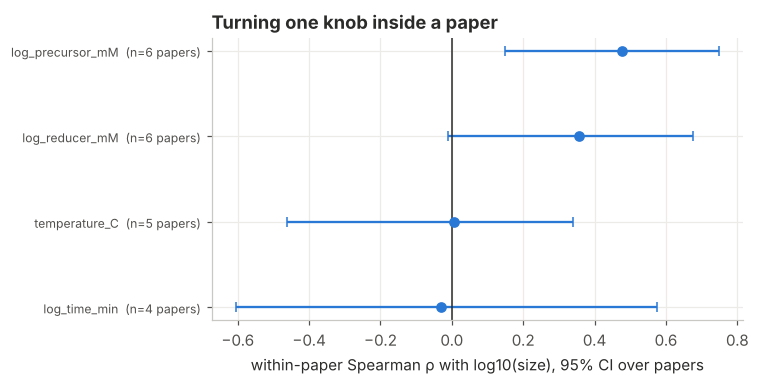

In [11]:
icc = U.icc_between_papers(size_df["log_size"], size_df["paper"])
print(f"ICC (share of log-size variance explained by paper identity): {icc:.2f}")

eff_feats = [f for f in NUM if f != "has_stabilizer"]
eff = U.within_paper_effects(size_df, eff_feats, "log_size", "paper", n_boot=1000, seed=SEED)
display(eff.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
e = eff.dropna().iloc[::-1]
ax.errorbar(e["within_paper_rho"], range(len(e)), xerr=[e["within_paper_rho"] - e["ci_low"], e["ci_high"] - e["within_paper_rho"]],
            fmt="o", color=U.BLUE, capsize=3)
ax.axvline(0, color=U.INK, lw=1); ax.set_yticks(range(len(e)))
ax.set_yticklabels([f"{i}  (n={int(r.n_papers)} papers)" for i, r in e.iterrows()], fontsize=8)
ax.set_xlabel("within-paper Spearman ρ with log10(size), 95% CI over papers")
ax.set_title("Turning one knob inside a paper"); plt.tight_layout(); plt.show()

## 6. Evaluation protocol

* **Splits:** 5-fold, repeated 5 times with different shuffles, always **grouped by paper**. Every score is on papers unseen in training.
* **Leakage control:** imputation, scaling, encoding and hyper-parameter search all happen *inside* each training fold (nested CV: the inner search also groups by paper).
* **Baselines:** global median; median **per nanoparticle family** (the "silver is about 30 nm" prior). A model only matters if it beats these.
* **Size metric:** mean absolute error in log10 units. `fold_error = 10^MAE`, so `1.8` means "typically off by a factor of 1.8". `within_2x` is the share of predictions within a factor of 2.
* **Uncertainty:** paired bootstrap over **papers** for the difference between a model and a baseline.

## 7. Size prediction

In [12]:
Xs, ys, gs = size_df[FEATURES], size_df["log_size"].to_numpy(), size_df["paper"].to_numpy()
zoo = U.regression_zoo(NUM, CAT + MEAS, seed=SEED)

oof_size, score_size = {}, {}
for name, est in zoo.items():
    oof_size[name], score_size[name] = U.repeated_group_cv(est, Xs, ys, gs, "reg", n_repeats=N_REPEATS, seed=SEED)
    print(f"{name:32s} done")

tbl = pd.concat({k: v.mean() for k, v in score_size.items()}, axis=1).T
tbl["MAE_log10 sd"] = [v["MAE_log10"].std() for v in score_size.values()]
display(tbl[["fold_error", "MAE_log10", "MAE_log10 sd", "R2_log", "within_2x", "median_abs_err_nm"]].round(3))

Baseline: global median          done
Baseline: median per NP family   done


Ridge                            done


Random forest                    done


Gradient boosting                done


,fold_error,MAE_log10,MAE_log10 sd,R2_log,within_2x,median_abs_err_nm
Baseline: global median,2.147,0.332,0.004,-0.040,0.596,16.562
Baseline: median per NP family,2.306,0.363,0.010,-0.038,0.493,21.378
Ridge,2.143,0.330,0.035,-0.069,0.550,14.879
Random forest,2.052,0.311,0.038,0.034,0.596,13.042
Gradient boosting,2.375,0.373,0.050,-0.263,0.510,20.316


**Is any model better than the baselines?** Paired bootstrap over papers: negative values mean the model's error is *lower* than the baseline's. If the 95% interval includes 0, the data cannot distinguish them.

,model,vs,ΔMAE_log10,95% CI low,95% CI high,significant
0,Ridge,global median,-0.002,-0.033,0.030,no
1,Ridge,median per NP family,-0.033,-0.122,0.058,no
2,Random forest,global median,-0.021,-0.059,0.012,no
3,Random forest,median per NP family,-0.052,-0.132,0.029,no
4,Gradient boosting,global median,0.042,-0.016,0.090,no
5,Gradient boosting,median per NP family,0.011,-0.084,0.104,no


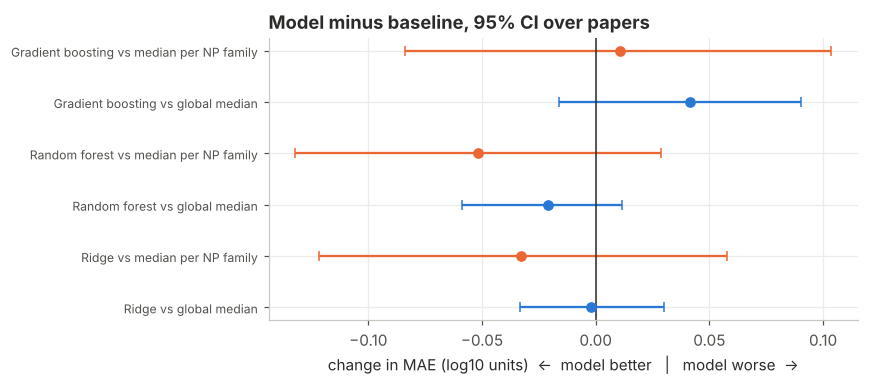

In [13]:
loss = {k: U.per_row_loss(ys, v, "reg") for k, v in oof_size.items()}
rows = []
for m in ["Ridge", "Random forest", "Gradient boosting"]:
    for b in ["Baseline: global median", "Baseline: median per NP family"]:
        d, (lo, hi) = U.paired_group_bootstrap(loss[m], loss[b], gs, seed=SEED)
        rows.append({"model": m, "vs": b.replace("Baseline: ", ""), "ΔMAE_log10": d, "95% CI low": lo, "95% CI high": hi,
                     "significant": "yes" if hi < 0 else ("worse" if lo > 0 else "no")})
cmp_size = pd.DataFrame(rows)
display(cmp_size.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in cmp_size.iterrows():
    col = U.BLUE if r["vs"].startswith("global") else U.ORANGE
    ax.errorbar(r["ΔMAE_log10"], i, xerr=[[r["ΔMAE_log10"] - r["95% CI low"]], [r["95% CI high"] - r["ΔMAE_log10"]]],
                fmt="o", color=col, capsize=3, ms=6)
ax.axvline(0, color=U.INK, lw=1)
ax.set_yticks(range(len(cmp_size))); ax.set_yticklabels([f"{m} vs {v}" for m, v in zip(cmp_size["model"], cmp_size["vs"])], fontsize=8)
ax.set_xlabel("change in MAE (log10 units)  ←  model better   |   model worse  →")
ax.set_title("Model minus baseline, 95% CI over papers")
plt.tight_layout(); plt.show()

best model on MAE: Random forest


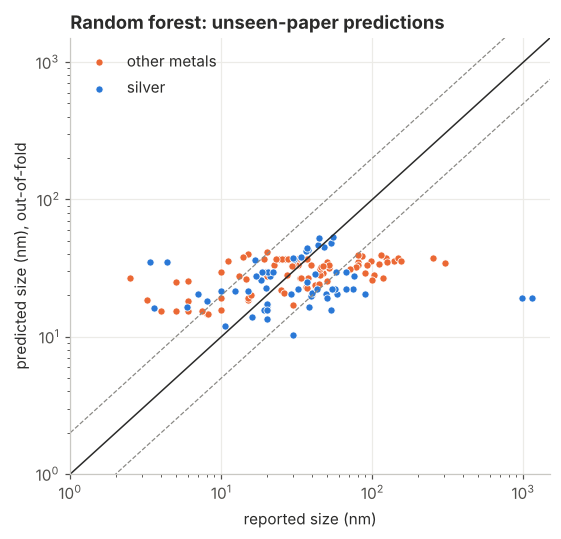

In [14]:
best = tbl.loc[[k for k in tbl.index if not k.startswith("Baseline")], "MAE_log10"].idxmin()
print("best model on MAE:", best)
pred = oof_size[best].mean(axis=0)
fig, ax = plt.subplots(figsize=(5.2, 5))
is_ag = (size_df["np_family"] == "Ag").to_numpy()
ax.scatter(10 ** ys[~is_ag], 10 ** pred[~is_ag], s=22, color=U.ORANGE, edgecolor="white", linewidth=.5, label="other metals")
ax.scatter(10 ** ys[is_ag],  10 ** pred[is_ag],  s=22, color=U.BLUE,   edgecolor="white", linewidth=.5, label="silver")
lim = [1, 1500]; ax.plot(lim, lim, color=U.INK, lw=1); ax.plot(lim, [l * 2 for l in lim], "--", color=U.GREY, lw=.8); ax.plot(lim, [l / 2 for l in lim], "--", color=U.GREY, lw=.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("reported size (nm)"); ax.set_ylabel("predicted size (nm), out-of-fold")
ax.set_title(f"{best}: unseen-paper predictions"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Which inputs matter? Ablation and permutation importance

**Ablation.** Add feature groups one at a time (Random forest, fixed hyper-parameters, same grouped CV). If a group does not lower the error, it is not helping on new papers.

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

def rf_reg(num, cat):
    return Pipeline([("pre", U.make_preprocessor(num, cat)),
                     ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6, random_state=SEED, n_jobs=2))])

sets = {
    "1. family only":                         ([], ["np_family"]),
    "2. + reagent classes":                   ([], ["np_family", "reducer_class", "stabilizer_class", "agitation_class"]),
    "3. + numeric recipe (conc., T, time)":   (NUM, CAT),
    "4. + measurement method":                (NUM, CAT + MEAS),
}
rows = []
for name, (num, cat) in sets.items():
    _, sc = U.repeated_group_cv(rf_reg(num, cat), Xs[num + cat], ys, gs, "reg", n_repeats=N_REPEATS, seed=SEED)
    rows.append({"features": name, "MAE_log10": sc["MAE_log10"].mean(), "sd": sc["MAE_log10"].std(), "fold_error": sc["fold_error"].mean()})
base = score_size["Baseline: median per NP family"]["MAE_log10"].mean()
rows.append({"features": "(reference) median per family", "MAE_log10": base, "sd": score_size["Baseline: median per NP family"]["MAE_log10"].std(),
             "fold_error": 10 ** base})
ablation = pd.DataFrame(rows).set_index("features"); display(ablation.round(3))

,MAE_log10,sd,fold_error
features,,,
1. family only,0.322,0.013,2.101
2. + reagent classes,0.318,0.038,2.086
"3. + numeric recipe (conc., T, time)",0.321,0.035,2.098
4. + measurement method,0.321,0.043,2.105
(reference) median per family,0.363,0.010,2.305


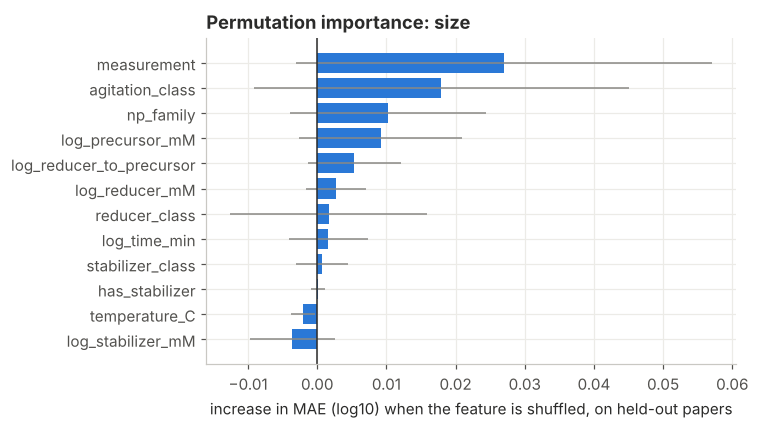

,importance,sd_over_folds
measurement,0.0270,0.0301
agitation_class,0.0179,0.0271
np_family,0.0102,0.0142
log_precursor_mM,0.0092,0.0118
log_reducer_to_precursor,0.0054,0.0068
log_reducer_mM,0.0027,0.0044
reducer_class,0.0017,0.0142
log_time_min,0.0016,0.0057
stabilizer_class,0.0007,0.0038
has_stabilizer,0.0001,0.0010


In [16]:
imp = U.grouped_permutation_importance(rf_reg(NUM, CAT + MEAS), Xs, ys, gs, "reg", n_perm=15, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
imp_plot = imp.iloc[::-1]
ax.barh(imp_plot.index, imp_plot["importance"], xerr=imp_plot["sd_over_folds"], color=U.BLUE, error_kw=dict(ecolor=U.GREY, lw=1))
ax.axvline(0, color=U.INK, lw=1)
ax.set_xlabel("increase in MAE (log10) when the feature is shuffled, on held-out papers")
ax.set_title("Permutation importance: size"); plt.tight_layout(); plt.show()
display(imp.round(4))

## 9. Shape prediction (spherical vs non-spherical)

Metrics: **ROC-AUC** (0.5 = chance), **PR-AUC** (compare with the positive rate), **Brier score** (lower is better) and balanced accuracy. Plain accuracy is not used: always answering "spherical" already scores high.

In [17]:
Xc, yc, gc = shape_df[FEATURES], shape_df["is_nonspherical"].to_numpy(), shape_df["paper"].to_numpy()
print(f"positive rate (non-spherical): {yc.mean():.2f}; always-'spherical' accuracy: {1 - yc.mean():.2f}")
zoo_c = U.classification_zoo(NUM, CAT + MEAS, seed=SEED)

oof_shape, score_shape = {}, {}
for name, est in zoo_c.items():
    oof_shape[name], score_shape[name] = U.repeated_group_cv(est, Xc, yc, gc, "clf", n_repeats=N_REPEATS, seed=SEED)
    print(f"{name:32s} done")
tbl_c = pd.concat({k: v.mean() for k, v in score_shape.items()}, axis=1).T
tbl_c["ROC_AUC sd"] = [v["ROC_AUC"].std() for v in score_shape.values()]
display(tbl_c[["ROC_AUC", "ROC_AUC sd", "PR_AUC", "Brier", "balanced_acc@0.5"]].round(3))

positive rate (non-spherical): 0.37; always-'spherical' accuracy: 0.63


Baseline: class prior            done


Baseline: prior per NP family    done


Logistic regression              done


Random forest                    done


,ROC_AUC,ROC_AUC sd,PR_AUC,Brier,balanced_acc@0.5
Baseline: class prior,0.500,0.000,0.326,0.254,0.500
Baseline: prior per NP family,0.656,0.086,0.519,0.255,0.584
Logistic regression,0.657,0.088,0.543,0.233,0.542
Random forest,0.666,0.048,0.541,0.213,0.538


In [18]:
loss_c = {k: U.per_row_loss(yc, v, "clf") for k, v in oof_shape.items()}
rows = []
for m in ["Logistic regression", "Random forest"]:
    for b in ["Baseline: class prior", "Baseline: prior per NP family"]:
        d, (lo, hi) = U.paired_group_bootstrap(loss_c[m], loss_c[b], gc, seed=SEED)
        rows.append({"model": m, "vs": b.replace("Baseline: ", ""), "ΔBrier": d, "95% CI low": lo, "95% CI high": hi,
                     "significant": "yes" if hi < 0 else ("worse" if lo > 0 else "no")})
cmp_shape = pd.DataFrame(rows); display(cmp_shape.round(3))

,model,vs,ΔBrier,95% CI low,95% CI high,significant
0,Logistic regression,class prior,-0.020,-0.107,0.054,no
1,Logistic regression,prior per NP family,-0.021,-0.103,0.063,no
2,Random forest,class prior,-0.040,-0.104,0.016,no
3,Random forest,prior per NP family,-0.041,-0.104,0.027,no


## 10. Conclusions

**What the numbers say** (147 size rows from 39 papers; 103 shape rows from 34 papers; all scores are on papers the model never saw).

* **Size.** The best model (random forest) is typically off by a factor of **2.05**. Predicting the global median gives **2.15**; the per-family median gives **2.31**. The paired bootstrap over papers puts the random forest's improvement over the global median at −0.021 log10 units, 95% CI [−0.059, 0.012]: *the data cannot tell the model from the baseline.* Ridge and gradient boosting do no better. The scatter plot shows why: predictions collapse into a 15–40 nm band whatever the true size.
* **Ablation.** Nanoparticle family alone (MAE 0.322) is as good as every richer feature set (0.318–0.321). Concentrations, temperature, time and reagent classes add nothing measurable for a new paper.
* **Between-paper variation dominates.** The ICC is 0.57: more than half the variance in log-size is explained by *which paper* a row comes from. Permutation importance ranks the **measurement method** (SEM, TEM, DLS...) first, though with a wide interval (0.027 ± 0.030). Part of what looks like "chemistry" is how the sizes were measured.
* **A real, within-paper signal exists for concentration.** When the same paper varies the precursor concentration, size tends to rise: within-paper Spearman ρ = **0.48** (95% CI 0.15–0.75; 6 papers, 61 rows). Reducing-agent concentration points the same way (0.36, CI −0.01–0.68). Temperature and time show no clear effect, but only 4–5 papers vary them.
* **Shape (spherical vs non-spherical, 37% non-spherical).** Random forest ROC-AUC 0.67 against 0.66 for "use the family's non-spherical rate" (0.50 is chance). Brier score improvements (−0.04) have a CI that includes 0. Whatever signal there is sits at the *nanoparticle-family* level.

**Reading across the two analyses (initial vs re-evaluation).** The initial result (R² = 0.85 for size, 91% shape accuracy) came from a random row split. With every paper held out, the same data gives no reliable advantage over simple baselines. That is not evidence that nanoparticle size is unpredictable; it shows that *this dataset*, with 39 papers and 1–18 rows each, cannot support a recipe-to-size model that generalises across labs.

**What would change this**
1. Data with many controlled variations *per paper* (one-factor-at-a-time or designed experiments), because these are what identify knob effects.
2. Standard reporting: units, measurement method and full recipes. Mass-based and percentage concentrations could not be converted to mM and were left missing (18% of precursor values, 20% of reducing-agent values, over half of the stabiliser values).
3. Per-paper random effects (mixed models) or Bayesian hierarchical models that separate the lab-level offset from the recipe effect, and report calibrated uncertainty.
4. Language-model-assisted extraction with human spot-checks, to scale beyond ~40 papers; extraction errors then become a measurable noise source.

**Limitations of this notebook.** Feature classes (reducing-agent type, stabiliser type) are hand-written rules; the unit assumptions (`mol` read as mol/L, `Mm` as mM) are unverified; small hyper-parameter grids and 5 repeats; the two largest sizes (≈1,000 nm, both silver) are kept (their influence is damped by the log transform); ICC and within-paper effects are estimated from few papers and should be read as indicative.